# Análisis exploratorio histórico 2009--2024

**Proyecto:** Hackea la participación: Datos que construyen democracia  
**Reto 1:** Perfiles ciudadanos de participación  
**Etapa:** Análisis exploratorio previo al clustering

## Objetivo

Analizar la base histórica comparable de 2,496 unidades con trayectoria completa en las seis elecciones para:

- revisar la distribución de la participación por año;
- estudiar la relación entre elecciones;
- observar diferencias por edad, sexo y tipo de sección;
- revisar el efecto potencial de los grupos pequeños;
- definir qué variables entrarán al modelo de segmentación.

> Los promedios calculados en este notebook son promedios de **unidades de análisis**. No deben interpretarse como tasas nacionales de participación, ya que cada unidad representa poblaciones de tamaños distintos.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


## 1. Carga de la base histórica comparable

Se utiliza el archivo generado por el notebook de integración histórica:

`base_historica_comparable_2009_2024.csv`


In [2]:
RUTA_BASE = "/content/base_historica_comparable_2009_2024.csv"

if not os.path.exists(RUTA_BASE):
    print("No se encontró la base en /content/.")
    print("Sube base_historica_comparable_2009_2024.csv")

    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass

if not os.path.exists(RUTA_BASE):
    raise FileNotFoundError(
        "Falta /content/base_historica_comparable_2009_2024.csv"
    )

df = pd.read_csv(RUTA_BASE, low_memory=False)

print("Dimensiones:", df.shape)
display(df.head())


Dimensiones: (2496, 17)


,EDONOM,GRUPO_EDAD,SEXO_DESC,TIPOSEC_DESC,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024,ANIOS_DISPONIBLES,PROMEDIO_HIST,STD_HIST,PART_RECIENTE,CAMBIO_2009_2024,TENDENCIA_ANUAL,ALGUN_GRUPO_PEQUENO
0,AGUASCALIENTES,18-19,Hombre,Mixta,36.785329,51.249306,27.240223,47.432339,45.313640,52.481618,6,43.417076,8.840246,52.481618,15.696289,0.770158,False
1,AGUASCALIENTES,18-19,Hombre,Rural,36.742757,54.276449,33.788820,51.050822,52.475667,51.201260,6,46.589296,8.121203,51.201260,14.458504,0.801449,False
2,AGUASCALIENTES,18-19,Hombre,Urbana,37.727104,56.572840,31.144422,53.581582,42.256591,49.969146,6,45.208614,8.985208,49.969146,12.242042,0.387606,False
3,AGUASCALIENTES,18-19,Mujer,Mixta,42.102665,58.915176,33.280934,55.596826,52.845828,60.411775,6,50.525534,9.725795,60.411775,18.309110,0.910985,False
4,AGUASCALIENTES,18-19,Mujer,Rural,49.355083,65.429609,44.783307,61.058824,65.961692,64.677716,6,58.544372,8.368328,64.677716,15.322633,0.899856,False


## 2. Validación inicial

La base comparable debe contener exactamente 2,496 unidades y las seis tasas históricas de participación.


In [3]:
ANIOS = [2009, 2012, 2015, 2018, 2021, 2024]
PART_COLS = [f"PART_{anio}" for anio in ANIOS]

LLAVES = [
    "EDONOM",
    "GRUPO_EDAD",
    "SEXO_DESC",
    "TIPOSEC_DESC"
]

esperadas = LLAVES + PART_COLS
faltantes = [c for c in esperadas if c not in df.columns]

if faltantes:
    raise ValueError(f"Faltan columnas esperadas: {faltantes}")

duplicados = df.duplicated(LLAVES).sum()
faltantes_part = df[PART_COLS].isna().sum().sum()

print("Unidades:", len(df))
print("Duplicados de llave:", duplicados)
print("Valores faltantes en tasas históricas:", faltantes_part)

if len(df) != 2496:
    print("ADVERTENCIA: la base no tiene exactamente 2,496 unidades.")

if duplicados != 0:
    raise ValueError("Existen llaves duplicadas.")

if faltantes_part != 0:
    raise ValueError("Existen tasas históricas faltantes.")

print("\nValidación inicial: OK")


Unidades: 2496
Duplicados de llave: 0
Valores faltantes en tasas históricas: 0

Validación inicial: OK


## 3. Resumen descriptivo de la participación por elección

Esta tabla permite comparar la distribución de las tasas entre unidades de análisis en cada proceso electoral.

**Importante:** `mean` es el promedio simple de las unidades, no la participación nacional.


In [4]:
resumen_participacion = (
    df[PART_COLS]
    .describe()
    .T
    .rename_axis("ELECCION")
)

display(resumen_participacion)

promedios_unidades = pd.Series(
    {anio: df[f"PART_{anio}"].mean() for anio in ANIOS},
    name="PROMEDIO_UNIDADES"
)

print("\nPromedio simple de las unidades por elección:")
display(promedios_unidades.to_frame())


,count,mean,std,min,25%,50%,75%,max
ELECCION,,,,,,,,
PART_2009,2496.0,48.019570,13.320111,0.000000,38.399039,48.380940,57.829256,79.468193
PART_2012,2496.0,64.428468,10.908805,32.276206,56.720632,65.773935,72.777076,93.392240
PART_2015,2496.0,52.302067,14.682892,15.124098,41.794996,53.003740,62.970935,93.040201
PART_2018,2496.0,63.803568,11.055101,27.961297,55.953979,64.601567,72.366948,93.000838
PART_2021,2496.0,55.834385,13.364846,13.207547,46.119716,56.763495,65.688526,89.697885
PART_2024,2496.0,61.266766,12.712677,25.401190,52.334344,62.389453,70.815752,91.531532



Promedio simple de las unidades por elección:


,PROMEDIO_UNIDADES
2009,48.019570
2012,64.428468
2015,52.302067
2018,63.803568
2021,55.834385
2024,61.266766


## 4. Distribución de las tasas por año

Se utiliza un diagrama de cajas únicamente como apoyo exploratorio para observar cambios en mediana, dispersión y valores extremos.


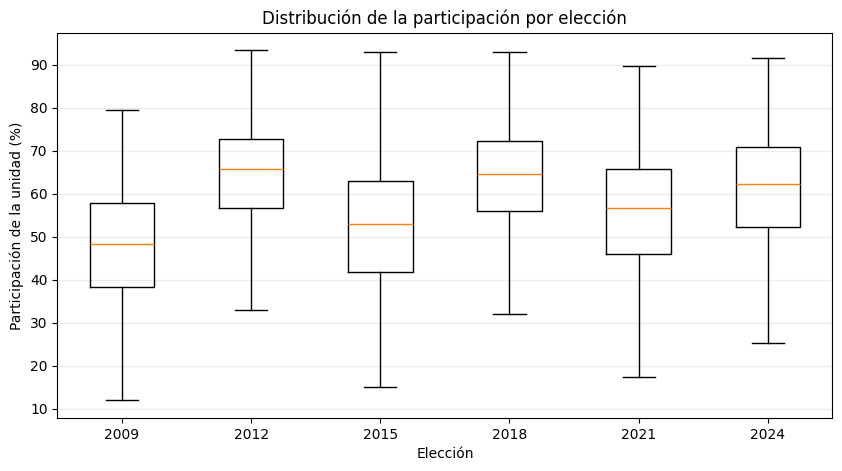

In [5]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    [df[col].dropna() for col in PART_COLS],
    tick_labels=[str(a) for a in ANIOS],
    showfliers=False
)

plt.xlabel("Elección")
plt.ylabel("Participación de la unidad (%)")
plt.title("Distribución de la participación por elección")
plt.grid(axis="y", alpha=0.25)
plt.show()


## 5. Correlación entre elecciones

Una correlación elevada indicaría que los grupos que tienden a participar más en una elección también tienden a hacerlo en otras.

La correlación no determina por sí sola qué variables deben eliminarse. Su función aquí es diagnosticar cuánta información compartida existe entre las seis elecciones.


,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024
PART_2009,1.000,0.829,0.830,0.689,0.703,0.695
PART_2012,0.829,1.000,0.819,0.906,0.843,0.877
PART_2015,0.830,0.819,1.000,0.763,0.759,0.732
PART_2018,0.689,0.906,0.763,1.000,0.884,0.911
PART_2021,0.703,0.843,0.759,0.884,1.000,0.902
PART_2024,0.695,0.877,0.732,0.911,0.902,1.000


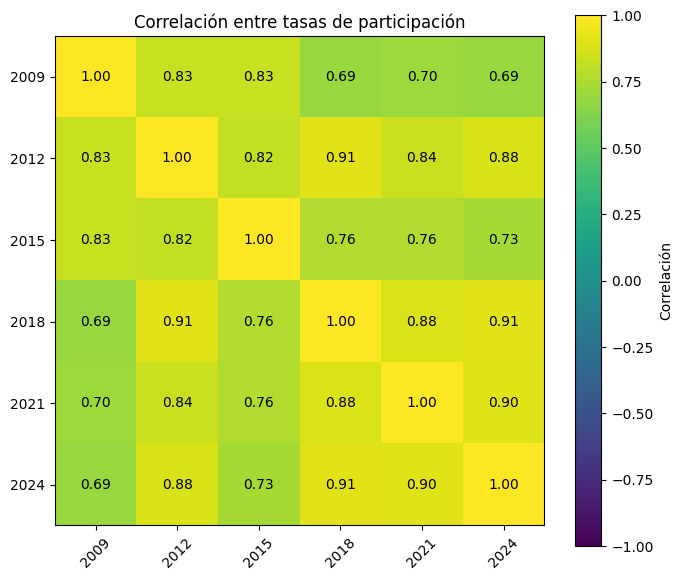

In [6]:
corr_part = df[PART_COLS].corr()

display(corr_part.round(3))

plt.figure(figsize=(7, 6))
im = plt.imshow(corr_part.values, vmin=-1, vmax=1)
plt.colorbar(im, label="Correlación")

plt.xticks(range(len(PART_COLS)), ANIOS, rotation=45)
plt.yticks(range(len(PART_COLS)), ANIOS)

for i in range(len(PART_COLS)):
    for j in range(len(PART_COLS)):
        plt.text(
            j, i,
            f"{corr_part.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlación entre tasas de participación")
plt.tight_layout()
plt.show()


## 6. Variables históricas derivadas

Las variables `PROMEDIO_HIST`, `STD_HIST`, `CAMBIO_2009_2024` y `TENDENCIA_ANUAL` resumen la misma trayectoria contenida en las seis tasas.

Por ello, se utilizarán principalmente para **interpretar los perfiles**, no necesariamente como entradas simultáneas del K-means.


In [7]:
DERIVADAS = [
    c for c in [
        "PROMEDIO_HIST",
        "STD_HIST",
        "PART_RECIENTE",
        "CAMBIO_2009_2024",
        "TENDENCIA_ANUAL"
    ]
    if c in df.columns
]

if DERIVADAS:
    display(df[DERIVADAS].describe().T)

    corr_derivadas = df[PART_COLS + DERIVADAS].corr()
    print("\nCorrelaciones de las variables derivadas con las elecciones:")
    display(corr_derivadas.loc[DERIVADAS, PART_COLS].round(3))
else:
    print("No se encontraron variables derivadas en la base.")


,count,mean,std,min,25%,50%,75%,max
PROMEDIO_HIST,2496.0,57.609137,11.596192,24.544592,49.322977,58.582314,66.469102,89.871715
STD_HIST,2496.0,7.547314,2.808867,1.175455,5.542082,7.528707,9.337588,22.325445
PART_RECIENTE,2496.0,61.266766,12.712677,25.401190,52.334344,62.389453,70.815752,91.531532
CAMBIO_2009_2024,2496.0,13.247197,10.183320,-14.061493,6.039443,14.057078,20.370701,55.555556
TENDENCIA_ANUAL,2496.0,0.494812,0.638734,-1.315484,0.044196,0.521526,0.937144,3.633318



Correlaciones de las variables derivadas con las elecciones:


,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024
PROMEDIO_HIST,0.868,0.954,0.899,0.930,0.924,0.926
STD_HIST,-0.608,-0.153,-0.457,0.021,-0.116,-0.005
PART_RECIENTE,0.695,0.877,0.732,0.911,0.902,1.000
CAMBIO_2009_2024,-0.441,0.011,-0.172,0.237,0.206,0.339
TENDENCIA_ANUAL,-0.386,-0.006,-0.169,0.263,0.322,0.359


## 7. Patrones descriptivos por sexo

Se compara el promedio histórico de las unidades de hombres y mujeres.

Este análisis es descriptivo y no implica que el sexo deba utilizarse directamente como variable numérica del clustering.


In [8]:
if "PROMEDIO_HIST" not in df.columns:
    df["PROMEDIO_HIST"] = df[PART_COLS].mean(axis=1)

resumen_sexo = (
    df.groupby("SEXO_DESC", observed=True)
    .agg(
        UNIDADES=("PROMEDIO_HIST", "size"),
        PROMEDIO_HIST=("PROMEDIO_HIST", "mean"),
        MEDIANA_HIST=("PROMEDIO_HIST", "median")
    )
    .sort_values("PROMEDIO_HIST", ascending=False)
)

display(resumen_sexo.round(3))


,UNIDADES,PROMEDIO_HIST,MEDIANA_HIST
SEXO_DESC,,,
Mujer,1248,60.588,61.768
Hombre,1248,54.630,55.266


## 8. Patrones descriptivos por tipo de sección


In [9]:
resumen_seccion = (
    df.groupby("TIPOSEC_DESC", observed=True)
    .agg(
        UNIDADES=("PROMEDIO_HIST", "size"),
        PROMEDIO_HIST=("PROMEDIO_HIST", "mean"),
        MEDIANA_HIST=("PROMEDIO_HIST", "median")
    )
    .sort_values("PROMEDIO_HIST", ascending=False)
)

display(resumen_seccion.round(3))


,UNIDADES,PROMEDIO_HIST,MEDIANA_HIST
TIPOSEC_DESC,,,
Rural,832,60.409,61.811
Mixta,832,56.561,57.854
Urbana,832,55.858,56.745


## 9. Patrones descriptivos por grupo de edad

Se conserva el orden natural de los grupos de edad para observar posibles cambios generacionales en la participación.


,UNIDADES,PROMEDIO_HIST,MEDIANA_HIST
GRUPO_EDAD,,,
18-19,192,53.394,52.707
20-24,192,45.047,44.359
25-29,192,44.380,42.849
30-34,192,48.904,47.560
35-39,192,53.933,53.058
40-44,192,57.965,57.676
45-49,192,61.070,61.100
50-54,192,63.559,63.548
55-59,192,65.291,65.210


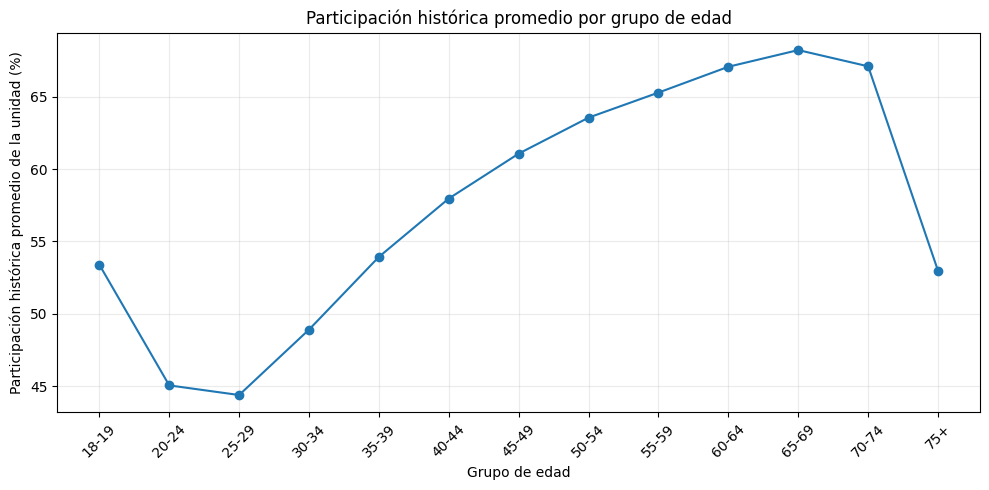

In [10]:
ORDEN_EDAD = [
    "18-19", "20-24", "25-29", "30-34",
    "35-39", "40-44", "45-49", "50-54",
    "55-59", "60-64", "65-69", "70-74", "75+"
]

resumen_edad = (
    df.groupby("GRUPO_EDAD", observed=True)
    .agg(
        UNIDADES=("PROMEDIO_HIST", "size"),
        PROMEDIO_HIST=("PROMEDIO_HIST", "mean"),
        MEDIANA_HIST=("PROMEDIO_HIST", "median")
    )
    .reindex(ORDEN_EDAD)
)

display(resumen_edad.round(3))

plt.figure(figsize=(10, 5))
plt.plot(
    resumen_edad.index,
    resumen_edad["PROMEDIO_HIST"],
    marker="o"
)
plt.xlabel("Grupo de edad")
plt.ylabel("Participación histórica promedio de la unidad (%)")
plt.title("Participación histórica promedio por grupo de edad")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 10. Revisión de grupos pequeños

Se revisa cuántas trayectorias tuvieron al menos un año con `N_DETERMINADO < 100`.

Esta variable se utilizará posteriormente para una prueba de sensibilidad: se comparará la solución de clustering con todos los grupos y excluyendo temporalmente las unidades marcadas.


In [11]:
if "ALGUN_GRUPO_PEQUENO" in df.columns:
    # Normalizar por si el CSV leyó el booleano como texto.
    if df["ALGUN_GRUPO_PEQUENO"].dtype == object:
        df["ALGUN_GRUPO_PEQUENO"] = (
            df["ALGUN_GRUPO_PEQUENO"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"true": True, "false": False})
        )

    print("Distribución:")
    display(df["ALGUN_GRUPO_PEQUENO"].value_counts(dropna=False))

    comparacion_pequenos = (
        df.groupby("ALGUN_GRUPO_PEQUENO", dropna=False)
        .agg(
            UNIDADES=("PROMEDIO_HIST", "size"),
            PROMEDIO_HIST=("PROMEDIO_HIST", "mean"),
            STD_PROMEDIO=("PROMEDIO_HIST", "std")
        )
    )

    display(comparacion_pequenos.round(3))
else:
    print("La base no contiene ALGUN_GRUPO_PEQUENO.")


Distribución:


,count
ALGUN_GRUPO_PEQUENO,
False,2470
True,26


,UNIDADES,PROMEDIO_HIST,STD_PROMEDIO
ALGUN_GRUPO_PEQUENO,,,
False,2470,57.712,11.560
True,26,47.839,11.025


## 11. Selección preliminar de variables para K-means

La propuesta principal es utilizar las **seis tasas históricas de participación**:

- `PART_2009`
- `PART_2012`
- `PART_2015`
- `PART_2018`
- `PART_2021`
- `PART_2024`

### Razón

Estas variables contienen directamente la trayectoria histórica de cada unidad. Los indicadores derivados (`PROMEDIO_HIST`, `STD_HIST`, `CAMBIO_2009_2024`, `TENDENCIA_ANUAL`) se calculan a partir de esas mismas tasas y añadirlos simultáneamente podría duplicar información.

Las variables demográficas y territoriales tampoco se codificarán inicialmente como números para formar los clusters. Se utilizarán posteriormente para **caracterizar e interpretar** cada perfil.

Antes del K-means, las seis tasas se estandarizan para que cada elección tenga la misma escala dentro del algoritmo. Esto también reduce el efecto de que elecciones con distinta participación general dominen el resultado únicamente por su nivel global.


In [12]:
X = df[PART_COLS].copy()

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

df_std = pd.DataFrame(
    X_std,
    columns=[f"Z_{anio}" for anio in ANIOS],
    index=df.index
)

print("Media de las variables estandarizadas:")
display(df_std.mean().round(6).to_frame("MEDIA"))

print("\nDesviación estándar poblacional:")
display(df_std.std(ddof=0).round(6).to_frame("STD"))

display(df_std.head())


Media de las variables estandarizadas:


,MEDIA
Z_2009,-0.0
Z_2012,-0.0
Z_2015,-0.0
Z_2018,-0.0
Z_2021,0.0
Z_2024,0.0



Desviación estándar poblacional:


,STD
Z_2009,1.0
Z_2012,1.0
Z_2015,1.0
Z_2018,1.0
Z_2021,1.0
Z_2024,1.0


,Z_2009,Z_2012,Z_2015,Z_2018,Z_2021,Z_2024
0,-0.843573,-1.208364,-1.707216,-1.481172,-0.787353,-0.691193
1,-0.846770,-0.930813,-1.261125,-1.153793,-0.251360,-0.791928
2,-0.772856,-0.720262,-1.441261,-0.924825,-1.016137,-0.888867
3,-0.444297,-0.505500,-1.295722,-0.742498,-0.223658,-0.067268
4,0.100283,0.091792,-0.512179,-0.248328,0.757909,0.268365


## 12. Exportación de insumos para clustering

Se genera una matriz estandarizada con las seis elecciones y una copia de la base comparable con el mismo índice de filas.


In [13]:
SALIDA_STD = "/content/matriz_clustering_estandarizada.csv"
SALIDA_RESUMEN = "/content/resumen_exploratorio_historico.csv"
SALIDA_CORR = "/content/correlaciones_participacion_2009_2024.csv"

matriz_clustering = pd.concat(
    [
        df[LLAVES].reset_index(drop=True),
        df_std.reset_index(drop=True)
    ],
    axis=1
)

matriz_clustering.to_csv(
    SALIDA_STD,
    index=False,
    encoding="utf-8-sig"
)

resumen_participacion.to_csv(
    SALIDA_RESUMEN,
    encoding="utf-8-sig"
)

corr_part.to_csv(
    SALIDA_CORR,
    encoding="utf-8-sig"
)

print("Archivos generados:")
print(" -", SALIDA_STD)
print(" -", SALIDA_RESUMEN)
print(" -", SALIDA_CORR)


Archivos generados:
 - /content/matriz_clustering_estandarizada.csv
 - /content/resumen_exploratorio_historico.csv
 - /content/correlaciones_participacion_2009_2024.csv


# Decisión metodológica preliminar

A partir de esta etapa, el modelo principal de segmentación utilizará las seis tasas de participación estandarizadas como variables de entrada.

Las variables de edad, sexo, entidad y tipo de sección se conservarán para describir posteriormente los conglomerados. Los indicadores históricos derivados se utilizarán principalmente para facilitar la interpretación de los perfiles.

La solución se evaluará inicialmente con:

$$
k \in \{4,5,6\}
$$

y se compararán:

- coeficiente de silueta;
- tamaño de los conglomerados;
- estabilidad frente a grupos pequeños;
- diferencias históricas entre los perfiles;
- interpretabilidad sociodemográfica y territorial.

El siguiente notebook aplicará K-means y realizará estas comparaciones.
